# Quickstart: Neural-ODE vector fields with exactly prescribed equilibria

This notebook shows how to use the `fpnode` library, in about four minutes on a CPU:

1. build a vector field whose equilibria are prescribed exactly, for every value of the trainable parameters;
2. train it by regression on samples of a target field, next to an unconstrained network of the same architecture;
3. compare the two models: residual at the equilibria, error over the domain, long-time trajectories.

The target is the Lotka-Volterra competition model of Section 5 of the paper, and the training protocol is that
of its Experiment 1 (50,000 samples, 400 epochs), for one seed; `02_paper_results.ipynb` shows the results of the
paper over all the seeds.

In [1]:
import sys
from pathlib import Path

try:
    import fpnode
except ImportError:  # running from a clone of the repository without `pip install -e .`
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import fpnode

import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from fpnode import FreeMLP, QRConstrainedMLP, data, metrics, plotting, set_seed
from fpnode.integrators import rk4_trajectory
from fpnode.training import train_fixed_epochs

torch.set_num_threads(4)

## 1. Target field and prescribed equilibria

$\dot x = x(3-x) - 2xy,\quad \dot y = y(2-y) - xy$ on $K=[-1,4]^2$. Its four equilibria $(0,0)$, $(0,2)$,
$(3,0)$ and $(1,1)$ are the prior knowledge injected into the model.

In [2]:
def target_field(x):
    X, Y = x[..., 0], x[..., 1]
    return torch.stack([X * (3 - X) - 2 * X * Y, Y * (2 - Y) - X * Y], dim=-1)


box = ((-1.0, 4.0), (-1.0, 4.0))
equilibria = torch.tensor([[0.0, 0.0], [0.0, 2.0], [3.0, 0.0], [1.0, 1.0]])
print("target field at the equilibria:", target_field(equilibria).tolist())

target field at the equilibria: [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]


## 2. A model with exactly prescribed equilibria

The model is $F_\theta(x) = -x + A\,\sigma(Bx+b) + d$ with $m$ hidden units. `QRConstrainedMLP` does not train
$A$ directly: at every forward pass it builds

$$A = Y S^+ + W\,(I - S S^+),$$

where $S$ collects the hidden features at the $C$ prescribed points, $Y = [\bar x^{(l)} - d]_l$ and $W$ is a free
matrix; $S^+$ is applied through a thin QR factorization of $S$ (Section 4 of the paper). Then
$F_\theta(\bar x^{(l)}) = 0$ for every value of $W$, $B$, $b$, $d$, which are trained as in an ordinary network.

In [3]:
set_seed(0)
model = QRConstrainedMLP(n_visible=2, m_hidden=256, equilibria=equilibria)
print("trainable parameters:", [name for name, _ in model.named_parameters()])
print(f"max_l |F(x_l)| at initialization:                 {model.fixed_point_residual():.1e}")

# The constraints do not depend on the values of the parameters: change all of them at random.
with torch.no_grad():
    for p in model.parameters():
        p.add_(torch.randn_like(p))
print(f"max_l |F(x_l)| after changing every parameter:    {model.fixed_point_residual():.1e}")

trainable parameters: ['W', 'd', 'B', 'b']
max_l |F(x_l)| at initialization:                 4.8e-07
max_l |F(x_l)| after changing every parameter:    3.7e-06


The residual is at single-precision round-off in both cases.

## 3. Training: constrained model and unconstrained network

Both models have the same architecture and initialization procedure of the paper and are trained on the same data
with the same optimizer (Adam, learning rate cosine-annealed from $10^{-3}$ to 0). `FreeMLP` trains $A = W$
directly. After every epoch we record the residual at the equilibria and the RMSE over a $250\times250$ grid of $K$.

In [4]:
x_train = data.sample_uniform(50_000, box, seed=0)
y_train = target_field(x_train)
grid = data.grid_points(box, 250)


def monitor(m):
    return {"fixed_point_residual": m.fixed_point_residual(),
            "grid_rmse": metrics.grid_rmse(m, target_field, grid)}


models, histories = {}, {}
for name, cls in [("QR-constrained", QRConstrainedMLP), ("Free MLP", FreeMLP)]:
    set_seed(0)
    models[name] = cls(n_visible=2, m_hidden=256, equilibria=equilibria)
    t0 = time.perf_counter()
    histories[name], _, _ = train_fixed_epochs(models[name], x_train, y_train, epochs=400, lr=1e-3,
                                               batch_size=500, schedule="cosine", monitor=monitor)
    print(f"{name:15s} {time.perf_counter() - t0:4.0f} s   grid RMSE {histories[name]['grid_rmse'][-1]:.1e}"
          f"   max_l |F(x_l)| {histories[name]['fixed_point_residual'][-1]:.1e}")

QR-constrained   133 s   grid RMSE 3.5e-03   max_l |F(x_l)| 3.3e-06


Free MLP         114 s   grid RMSE 2.1e-02   max_l |F(x_l)| 1.3e-02


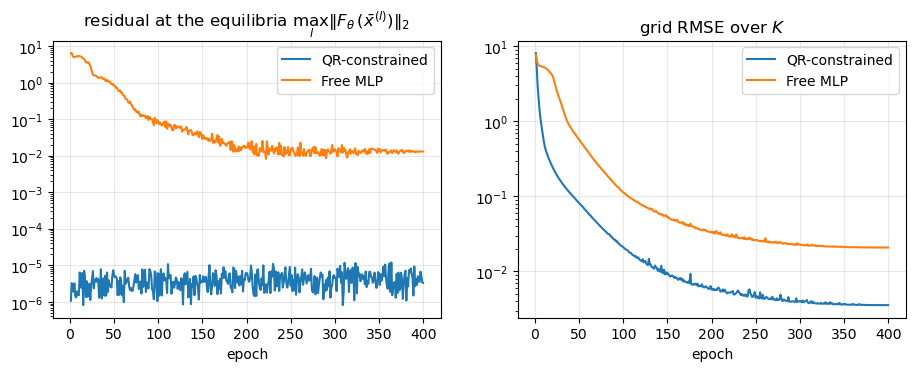

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, h in histories.items():
    axes[0].plot(np.arange(1, 401), h["fixed_point_residual"], label=name)
    axes[1].plot(np.arange(1, 401), h["grid_rmse"], label=name)
for ax, title in zip(axes, [r"residual at the equilibria $\max_l\|F_\theta(\bar x^{(l)})\|_2$",
                            "grid RMSE over $K$"]):
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

The residual of the constrained model stays at round-off level during the whole training, while the free
network matches the equilibria only as well as it fits the data. The learned field and its error over $K$
(red crosses: prescribed equilibria):

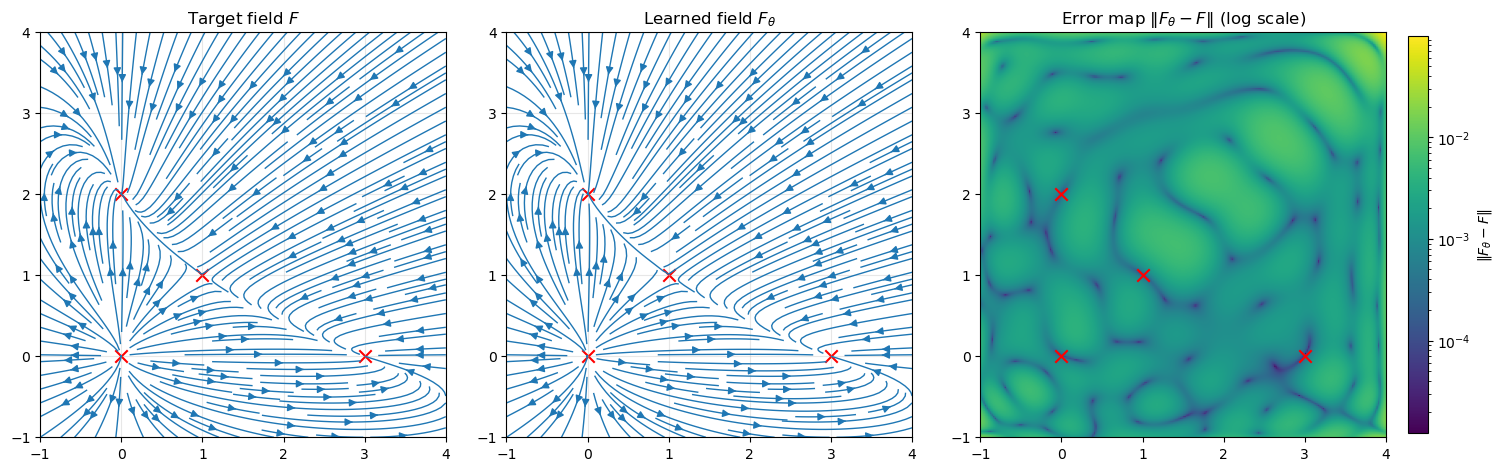

In [6]:
plotting.plot_field_comparison(target_field, models["QR-constrained"], box, equilibria.numpy(), close=False)
plt.show()

## 4. Long-time dynamics

We integrate the learned fields and the target field with RK4 ($\Delta t = 0.01$) from 200 initial conditions in
$[0.2, 3.5]^2$ up to $t = 30$. The trajectories of the constrained model converge to the exact equilibria; those of
the free network converge to slightly displaced equilibria, so their error does not vanish.

QR-constrained  error at t = 30 (geometric mean over the initial conditions): 5.7e-06


Free MLP        error at t = 30 (geometric mean over the initial conditions): 5.7e-03


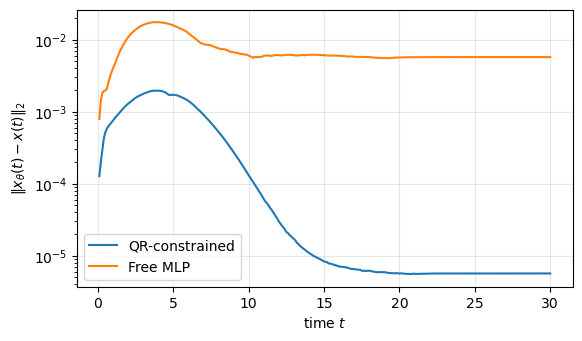

In [7]:
x0 = data.uniform_points(200, ((0.2, 3.5), (0.2, 3.5)), seed=123)
dt, n_steps, save_every = 0.01, 3000, 10
x_true = rk4_trajectory(lambda x: target_field(x.double()), x0.double(), dt, n_steps, save_every)
t = dt * save_every * np.arange(x_true.shape[0])

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for name, m in models.items():
    m.eval()
    x_learned = rk4_trajectory(m.field_fn(), x0, dt, n_steps, save_every)
    err = (x_learned - x_true).norm(dim=2).clamp_min(1e-300)  # [time, initial condition]
    ax.plot(t[1:], 10 ** err[1:].log10().mean(dim=1), label=name)
    print(f"{name:15s} error at t = 30 (geometric mean over the initial conditions): {10 ** err[-1].log10().mean():.1e}")
ax.set_yscale("log")
ax.set_xlabel("time $t$")
ax.set_ylabel(r"$\|x_\theta(t) - x(t)\|_2$")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5. Using the library on another system

Only samples of the field (or observed trajectories) and the prescribed points are needed:

```python
import torch
from fpnode import QRConstrainedMLP
from fpnode.losses import regression_loss

model = QRConstrainedMLP(n_visible=n, m_hidden=m, equilibria=points)   # points: [C, n] tensor, m >= C
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
for x, y in loader:                                                   # samples of the target field
    loss = regression_loss(model, x, y)                               # or any loss of model(x)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
```

* `PseudoinverseConstrainedMLP` builds the same family with an explicit pseudoinverse; the QR version is
  numerically preferable.
* `fpnode.training` has the training loops of the paper (fixed number of epochs; training until the validation
  error stops improving).
* `fpnode.losses.trajectory_loss` trains on observed trajectories, by backpropagation through RK4 (Appendix C).
* `regression_loss(model, x, y, penalty_lambda=...)` gives the soft-penalty baseline of the paper.
* The experiments of the paper are in `experiments/`; `python reproduce.py` regenerates their figures and tables.